In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import numpy as np



file_path = '/content/drive/My Drive/wood data/wood/X_ray/Diverse_XR.npy'


data = np.load(file_path, mmap_mode='r')
data_real = np.abs(data)

print("Data shape:", data.shape)

Data shape: (78, 135, 185)


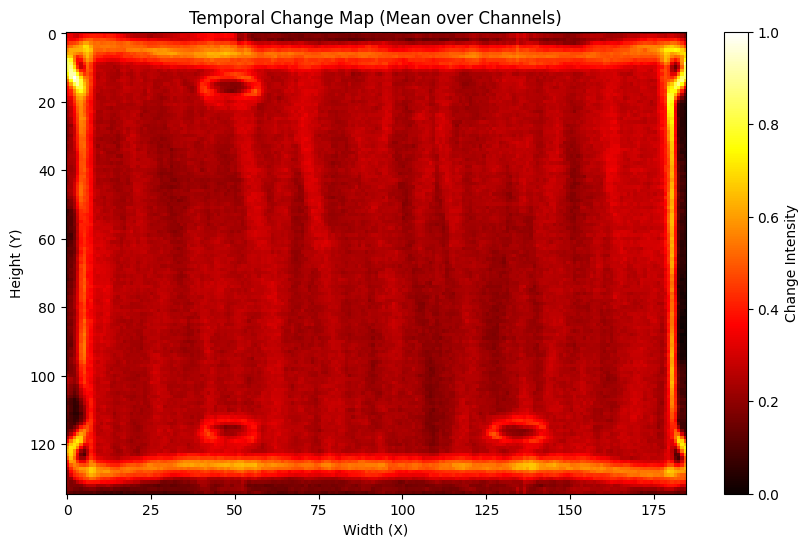

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


T, H, W = data.shape
temporal_diff = np.diff(data, axis=0)
change_map = np.sum(np.abs(temporal_diff), axis=0)
change_map_normalized = (change_map - change_map.min()) / np.ptp(change_map)
plt.figure(figsize=(10, 6))
plt.imshow(change_map_normalized, cmap='hot', aspect='auto')
plt.title("Temporal Change Map (Mean over Channels)")
plt.colorbar(label='Change Intensity')
plt.xlabel("Width (X)")
plt.ylabel("Height (Y)")
plt.show()

In [ ]:
import numpy as np
T, H, W = data_real.shape


temporal_std = np.std(data_real, axis=0)
has_change = temporal_std > 1e-6
changed_pixel_coords = np.argwhere(has_change)


print(f"\nTotal pixels with any temporal change: {len(changed_pixel_coords)}")


Total pixels with any temporal change: 24975


1. Darkest pixel at (16, 49) with STD = 167.3097
2. Darkest pixel at (117, 134) with STD = 175.6999
3. Darkest pixel at (117, 49) with STD = 189.4889


<ipython-input-22-240768027>:38: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(c, r, color='cyan', marker='x', s=100, edgecolors='black')


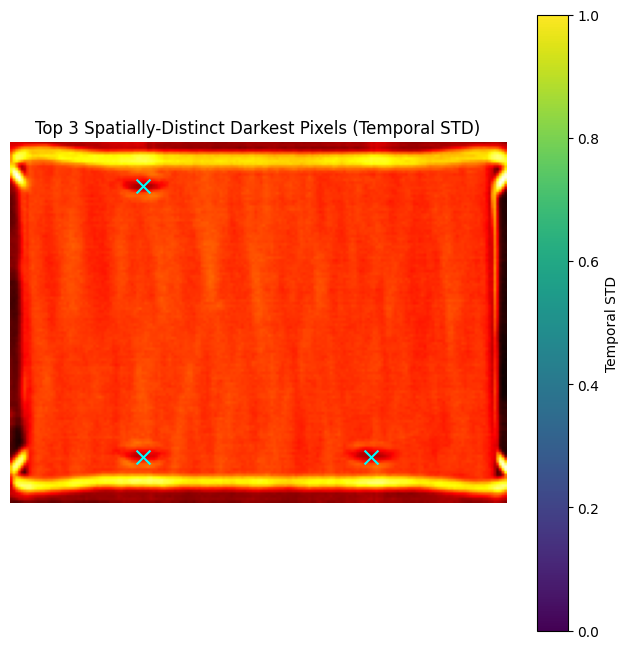

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
border = 10
num_darkest = 3
min_distance = 10

temporal_std = np.std(data_real, axis=0)


inner_std = temporal_std[border:-border, border:-border]


flat_indices = np.argsort(inner_std.ravel())
rows_inner, cols_inner = np.unravel_index(flat_indices, inner_std.shape)
rows_full = rows_inner + border
cols_full = cols_inner + border
coords_full = list(zip(rows_full, cols_full))


darkest_coords = []
for y, x in coords_full:
    if all(np.linalg.norm([y - py, x - px]) >= min_distance for py, px in darkest_coords):
        darkest_coords.append((y, x))
    if len(darkest_coords) == num_darkest:
        break


for i, (r, c) in enumerate(darkest_coords, 1):
    print(f"{i}. Darkest pixel at ({r}, {c}) with STD = {temporal_std[r, c]:.4f}")


plt.figure(figsize=(8, 8))
plt.imshow(temporal_std, cmap='hot')
for r, c in darkest_coords:
    plt.scatter(c, r, color='cyan', marker='x', s=100, edgecolors='black')

plt.title("Top 3 Spatially-Distinct Darkest Pixels (Temporal STD)")
plt.colorbar(label='Temporal STD')
plt.axis('off')
plt.show()

In [ ]:
for i, (r, c) in enumerate(darkest_coords, 1):
    std_value = temporal_std[r, c]
    print(f"{i}. Darkest pixel at (Y={r}, X={c}) with STD = {std_value:.4f}")


1. Darkest pixel at (Y=16, X=49) with STD = 167.3097
2. Darkest pixel at (Y=117, X=134) with STD = 175.6999
3. Darkest pixel at (Y=117, X=49) with STD = 189.4889


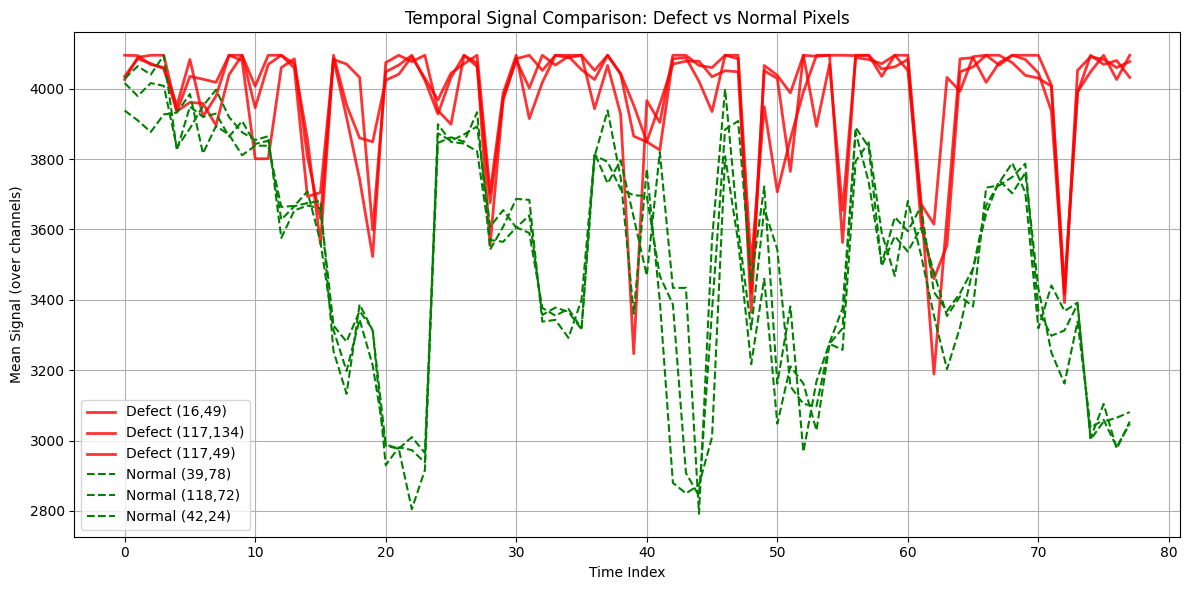

Random normal pixel coordinates:
Normal pixel at (Y=39, X=78)
Normal pixel at (Y=118, X=72)
Normal pixel at (Y=42, X=24)


In [ ]:
import random
defect_signals = []
for (y, x) in darkest_coords:
    signal = data_real[:, y, x]
    defect_signals.append((f"Defect ({y},{x})", signal))


random_coords = []
while len(random_coords) < 3:
    ry = random.randint(10, H - 11)
    rx = random.randint(10, W - 11)
    if all(np.linalg.norm([ry - dy, rx - dx]) >= 15 for dy, dx in darkest_coords):
        random_coords.append((ry, rx))
normal_signals = []
for (y, x) in random_coords:
    signal = data_real[:, y, x]
    normal_signals.append((f"Normal ({y},{x})", signal))


plt.figure(figsize=(12, 6))
for label, signal in defect_signals:
    plt.plot(signal, label=label, linewidth=2, color='red', alpha=0.8)

for label, signal in normal_signals:
    plt.plot(signal, label=label, linestyle='--', linewidth=1.5, color='green')

plt.title("Temporal Signal Comparison: Defect vs Normal Pixels")
plt.xlabel("Time Index")
plt.ylabel("Mean Signal (over channels)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print("Random normal pixel coordinates:")
for (y, x) in random_coords:
    print(f"Normal pixel at (Y={y}, X={x})")

Data shape: T=78, H=135, W=185
✅ Selected normal pixels: [(np.int64(124), np.int64(45)), (np.int64(124), np.int64(51)), (np.int64(124), np.int64(49))]


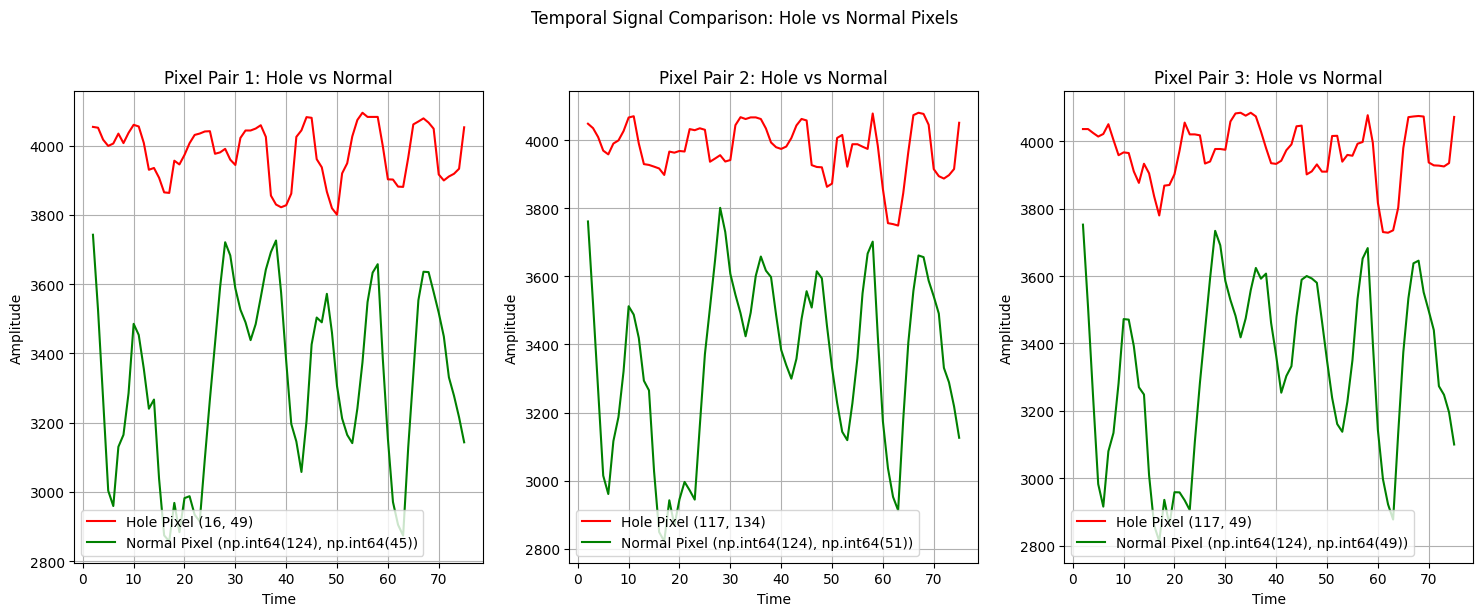

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


T, H, W = data_real.shape
print(f"Data shape: T={T}, H={H}, W={W}")


hole_pixels = [(16,49), (117, 134), (117, 49)]

temporal_std = np.std(data_real, axis=0)

pixel_activity = temporal_std

flat_indices = np.argsort(pixel_activity.ravel())[::-1]
normal_pixels = []

border = 10
for idx in flat_indices:
    h, w = np.unravel_index(idx, (H, W))

    if (h, w) not in hole_pixels and h >= border and h < H - border and w >= border and w < W - border:
        normal_pixels.append((h, w))
    if len(normal_pixels) >= 3:
        break

print(f"✅ Selected normal pixels: {normal_pixels}")



def smooth_curve(y, window=3):

    if window % 2 == 0:
      window += 1
    if window > 1:
      return np.convolve(y, np.ones(window)/window, mode='valid')
    else:
      return y


def plot_hole_vs_normal(data_real, hole_pixels, normal_pixels, smooth_window=1):

    plt.figure(figsize=(15, 6))

    for i, (hole, normal) in enumerate(zip(hole_pixels, normal_pixels)):
        plt.subplot(1, len(hole_pixels), i + 1)

        hole_signal = data_real[:, hole[0], hole[1]]
        normal_signal = data_real[:, normal[0], normal[1]]

        if smooth_window > 1:
            hole_signal = smooth_curve(hole_signal, smooth_window)
            normal_signal = smooth_curve(normal_signal, smooth_window)


            time_axis = np.arange(len(hole_signal)) + (smooth_window - 1) // 2
        else:
             time_axis = np.arange(len(hole_signal))


        plt.plot(time_axis, hole_signal, label=f'Hole Pixel {hole}', color='red')
        plt.plot(time_axis, normal_signal, label=f'Normal Pixel {normal}', color='green')
        plt.title(f'Pixel Pair {i+1}: Hole vs Normal')
        plt.xlabel('Time')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.legend()


    plt.suptitle('Temporal Signal Comparison: Hole vs Normal Pixels', y=1.02)
    plt.tight_layout()
    plt.show()


smooth_window = 5

plot_hole_vs_normal(data_real, hole_pixels, normal_pixels, smooth_window)

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 10.0 MB/s eta 0:00:00


R^2: 0.9996964297752461
MAE: 2.734054476138227


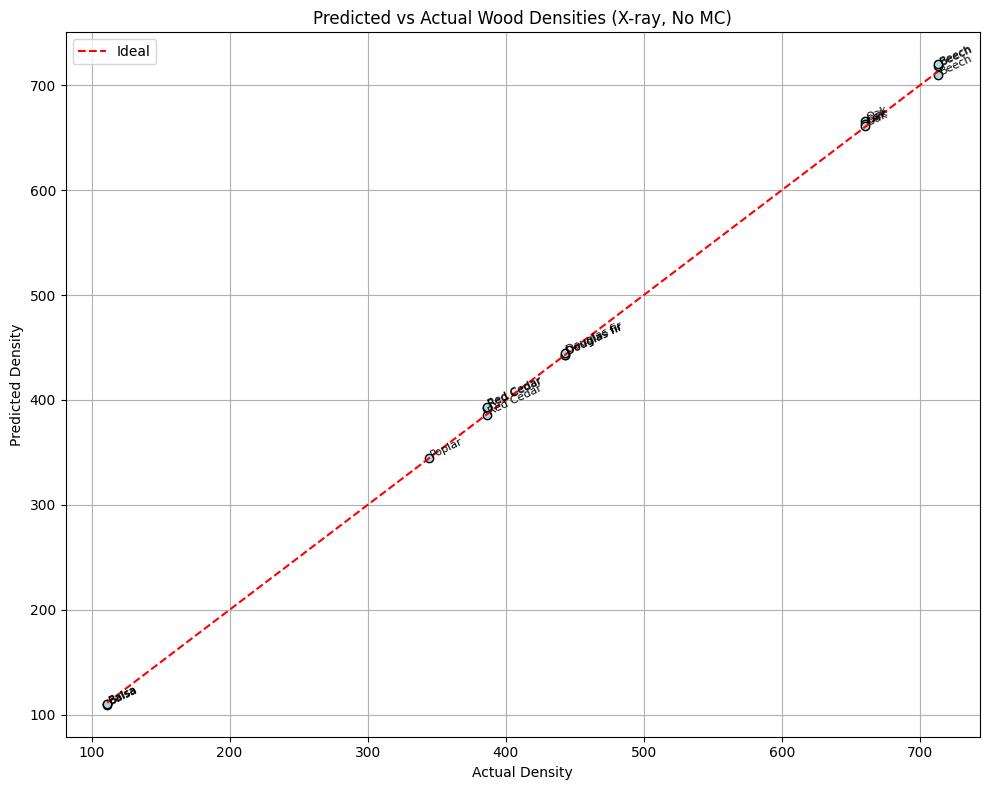

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


npy_path = '/content/drive/MyDrive/wood data/wood/X_ray/Copy of Diverse_XR.npy'
data_real = np.load(npy_path, mmap_mode='r')


df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Diverse_dimensions.csv')
df["Species"] = df["Species"].str.strip().str.lower()
density_col = [col for col in df.columns if 'density' in col.lower()][0]
species_density = dict(zip(df["Species"], df[density_col]))

sample_to_species = {
    "ABa": "Balsa", "BBa": "Balsa", "CBa": "Balsa", "DBa": "Balsa",
    "EBa": "Balsa", "FBa": "Balsa", "GBa": "Balsa", "HBa": "Balsa", "IBa": "Balsa",
    "JBa": "Balsa", "KBa": "Balsa", "LBa": "Balsa",
    "ABe": "Beech", "BBe": "Beech", "CBe": "Beech", "DBe": "Beech", "EBe": "Beech",
    "FBe": "Beech", "GBe": "Beech", "HBe": "Beech", "IBe": "Beech", "JBe": "Beech",
    "KBe": "Beech", "LBe": "Beech",
    "ACe": "Red Cedar", "BCe": "Red Cedar", "CCe": "Red Cedar", "DCe": "Red Cedar",
    "ECe": "Red Cedar", "FCe": "Red Cedar", "GCe": "Red Cedar", "HCe": "Red Cedar",
    "ICe": "Red Cedar", "JCe": "Red Cedar", "KCe": "Red Cedar", "LCe": "Red Cedar",
    "ADR": "Douglas fir", "BDR": "Douglas fir", "EDR": "Douglas fir", "FDR": "Douglas fir",
    "GDR": "Douglas fir", "HDR": "Douglas fir", "IDR": "Douglas fir", "JDR": "Douglas fir",
    "KDR": "Douglas fir", "LDR": "Douglas fir", "ADT": "Douglas fir", "BDT": "Douglas fir",
    "EDT": "Douglas fir", "FDT": "Douglas fir", "GDT": "Douglas fir", "HDT": "Douglas fir",
    "IDT": "Douglas fir", "JDT": "Douglas fir", "KDT": "Douglas fir", "LDT": "Douglas fir",
    "APo": "Poplar", "BPo": "Poplar", "EPo": "Poplar", "FPo": "Poplar", "GPo": "Poplar",
    "HPo": "Poplar", "IPo": "Poplar", "JPo": "Poplar", "KPo": "Poplar", "LPo": "Poplar",
    "AOa": "Oak", "BOa": "Oak", "COa": "Oak", "DOa": "Oak", "EOa": "Oak", "FOa": "Oak",
    "GOa": "Oak", "HOa": "Oak", "IOa": "Oak", "JOa": "Oak", "KOa": "Oak", "LOa": "Oak"
}

sample_ids_ordered = list(sample_to_species.keys())
species_list = [sample_to_species[sid] for sid in sample_ids_ordered]

if len(species_list) != data_real.shape[0]:
    raise ValueError("Species list and data mismatch.")

# --- Feature Extraction (No MC) ---
samples, labels, species_labels = [], [], []
for i, species in enumerate(species_list):
    dens = species_density.get(species.lower())
    if dens is None:
        continue

    sample = np.abs(data_real[i])
    if sample.ndim == 3:
        sample = sample[0]  # shape: (H, W)

    std_map = np.std(sample) if sample.ndim == 2 else sample
    coords = np.unravel_index(np.argsort(-sample.ravel())[:5], sample.shape)

    img_mean = np.mean(sample)
    img_std = np.std(sample)

    feat_vectors = []
    for r, c in zip(*coords):
        val = sample[r, c]
        feat_vectors.append([
            val,
            (val - img_mean),
            val / (img_mean + 1e-8)
        ])

    feat_avg = np.mean(feat_vectors, axis=0)
    mass = df.loc[i, "Mass (g)"]
    volume = (df.loc[i, "Length (mm)"] * df.loc[i, "Width (mm)"] * df.loc[i, "Thickness (mm)"]) / 1000

    # No Moisture Content
    features = list(feat_avg) + [img_mean, img_std, mass, volume]
    samples.append(features)
    labels.append(dens)
    species_labels.append(species)

# --- Preprocessing ---
X = StandardScaler().fit_transform(samples)
species_array = np.array(species_labels).reshape(-1, 1)
species_encoded = OneHotEncoder(sparse_output=False).fit_transform(species_array)
X_final = np.concatenate([X, species_encoded], axis=1)
y_log = np.log1p(labels)

# --- Train/Test Split ---
species_labels_np = np.array(species_labels)
X_train, X_test, y_train, y_test, species_train, species_test = train_test_split(
    X_final, y_log, species_labels_np, test_size=0.2, random_state=42, shuffle=True)

# --- Model ---
stack_model = StackingRegressor(
    estimators=[
        ('cat', CatBoostRegressor(verbose=0)),
        ('xgb', XGBRegressor(objective='reg:squarederror')),
        ('rf', RandomForestRegressor())
    ],
    final_estimator=Ridge()
)

# --- Train & Evaluate ---
stack_model.fit(X_train, y_train)
y_pred_log = stack_model.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)

print("R^2:", r2_score(y_true, y_pred))
print("MAE:", mean_absolute_error(y_true, y_pred))

# --- Plot ---
plt.figure(figsize=(10, 8))
plt.scatter(y_true, y_pred, c='lightblue', edgecolors='k')
for i, txt in enumerate(species_test):
    plt.annotate(txt, (y_true[i], y_pred[i]), fontsize=8, rotation=25)
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', label='Ideal')
plt.xlabel("Actual Density")
plt.ylabel("Predicted Density")
plt.title("Predicted vs Actual Wood Densities (X-ray, No MC)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

y_train_pred_log = stack_model.predict(X_train)
y_train_pred = np.expm1(y_train_pred_log)
y_train_true = np.expm1(y_train)

print("\n--- Training Performance ---")
print("Train R^2:", r2_score(y_train_true, y_train_pred))
print("Train MAE:", mean_absolute_error(y_train_true, y_train_pred))

print("\n--- Test Performance ---")
print("Test R^2:", r2_score(y_true, y_pred))
print("Test MAE:", mean_absolute_error(y_true, y_pred))




--- Training Performance ---
Train R^2: 0.999838888514783
Train MAE: 1.7485612039734924

--- Test Performance ---
Test R^2: 0.9996964297752461
Test MAE: 2.734054476138227


In [ ]:
import time


start_train = time.time()
stack_model.fit(X_train, y_train)
end_train = time.time()
train_time = end_train - start_train


start_test = time.time()
y_pred_log = stack_model.predict(X_test)
end_test = time.time()
test_time = end_test - start_test


y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)


print(f"Training time: {train_time:.2f} seconds")
print(f"Testing time: {test_time:.2f} seconds")


Training time: 6.22 seconds
Testing time: 0.01 seconds


In [ ]:

import pandas as pd

results_df = pd.DataFrame({
    'Species': species_test,
    'Actual Density': y_true,
    'Predicted Density': y_pred
})

results_df = results_df.sort_values(by='Species').reset_index(drop=True)


print(results_df)




        Species  Actual Density  Predicted Density
0         Balsa      111.327501         108.936933
1         Balsa      111.327501         111.754920
2         Balsa      111.327501         110.367878
3         Beech      713.137115         713.025854
4         Beech      713.137115         719.583232
5         Beech      713.137115         722.453042
6   Douglas fir      442.641229         443.398854
7   Douglas fir      442.641229         442.663817
8   Douglas fir      442.641229         444.307832
9           Oak      660.260719         667.003742
10          Oak      660.260719         663.737118
11          Oak      660.260719         662.219326
12       Poplar      344.307549         344.045442
13    Red Cedar      386.441537         385.863087
14    Red Cedar      386.441537         392.845475
15    Red Cedar      386.441537         393.135060


evaluation

LOSO Evaluation: 100%|██████████| 78/78 [09:28<00:00,  7.29s/it]



✅ LOSO with GridSearch:
R² Score: 0.9418
MAE: 24.12 kg/m³


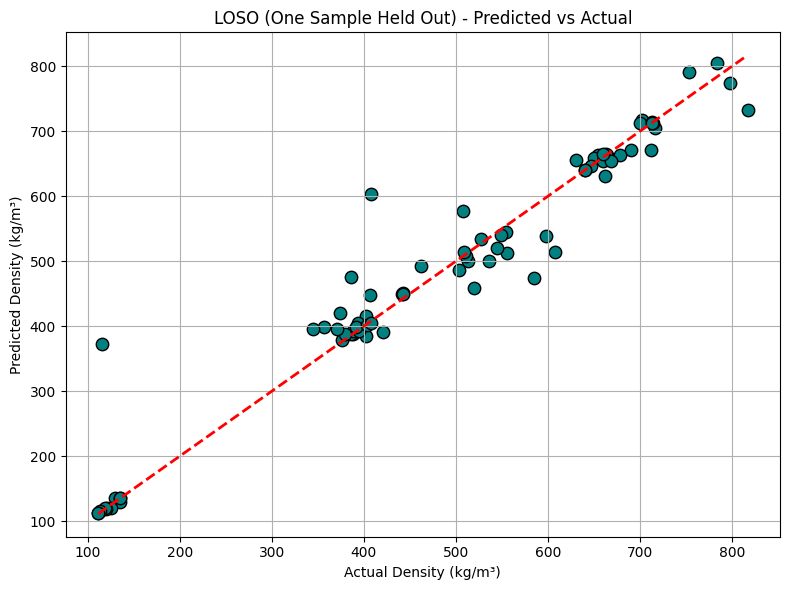

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft2
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
from tqdm import tqdm

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Diverse_dimensions.csv')
data_real = np.load('/content/drive/MyDrive/wood data/wood/X_ray/Copy of Diverse_XR.npy')

df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)


samples = []
labels = []

for i in range(data_real.shape[0]):
    image = np.abs(data_real[i])
    H, W = image.shape
    image_flat = image.reshape(-1)
    top_idxs = np.argsort(np.abs(image_flat - image_flat.mean()))[-5:]

    mass = df.loc[i, "Mass (g)"]
    volume = df.loc[i, "Volume_cm3"]
    mc_t = df.loc[i, "MC_t"]
    density = df.loc[i, "Density (kg/m3)"]

    for idx in top_idxs:
        h = idx // W
        w = idx % W
        pixel_val = image[h, w]

        patch_size = 5
        h0 = max(0, h - patch_size // 2)
        h1 = min(H, h + patch_size // 2 + 1)
        w0 = max(0, w - patch_size // 2)
        w1 = min(W, w + patch_size // 2 + 1)
        patch = image[h0:h1, w0:w1]

        spectrum2d = np.abs(fft2(patch))
        fft_mean = spectrum2d.mean()
        fft_peak = spectrum2d.max()

        features = [
            mass, volume, mc_t,
            pixel_val,
            patch.std(),
            fft_mean,
            fft_peak
        ]
        samples.append(features)
        labels.append(density)

X = pd.DataFrame(samples, columns=[
    "Mass", "Volume", "MC_t",
    "Pixel_Mean", "Pixel_Std",
    "FFT_Mean", "FFT_Peak"
])
y = np.array(labels)

num_samples = df.shape[0]
preds = []
true_vals = []

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}

for i in tqdm(range(num_samples), desc="LOSO Evaluation"):
    test_idx = list(range(i * 5, (i + 1) * 5))
    train_idx = list(set(range(len(X))) - set(test_idx))

    X_train = X.iloc[train_idx]
    y_train = y[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y[test_idx]

    grid = GridSearchCV(
        RandomForestRegressor(random_state=42),
        param_grid,
        cv=3,
        scoring='r2',
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test)
    preds.append(np.mean(y_pred))
    true_vals.append(y_test[0])


r2 = r2_score(true_vals, preds)
mae = mean_absolute_error(true_vals, preds)

print("\n LOSO with GridSearch:")
print("R² Score:", round(r2, 4))
print("MAE:", round(mae, 2), "kg/m³")


plt.figure(figsize=(8, 6))
plt.scatter(true_vals, preds, color='teal', edgecolor='k', s=80)
plt.plot([min(true_vals), max(true_vals)], [min(true_vals), max(true_vals)], 'r--', lw=2)
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("LOSO (One Sample Held Out) - Predicted vs Actual")
plt.grid(True)
plt.tight_layout()
plt.show()
